In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [ ]:
# 4: LIF driven by a synaptic transient

R, Tm, Ts, uth = 1, 10, 2, 1

def u_theory(t, I0, Tm = Tm, Ts = Ts):
    return R*I0*Ts/(Ts-Tm)*(np.exp(-t/Ts) - np.exp(-t/Tm))

def dudt(u, t, I0, uth = uth, Tm = Tm, Ts = Ts):
    return (1/Tm)*(-u + R*I0*np.exp(-(t/Ts)))

def tpeak_theory(Tm=Tm, Ts=Ts):
    return (Tm*Ts/(Ts-Tm))*np.log(Ts/Tm)

def Icrit_theory(Tm=Tm, Ts=Ts):
    r = (Ts/Tm)
    return (uth)/R * (r**(1/(r-1)))

In [51]:
t = np.linspace(0, 60, 600001)   # dt = 1e-4 ms

# solve to ODE using trap rule
def trap_rule(u_num, t, I0):
    u_num = np.zeros_like(t)

    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        if u_num[i-1] >= uth:
            u_num[i] = 0
        else:
            u_num[i] = u_num[i-1] + dt * dudt(u_num[i-1], t[i-1], I0=I0)

    return u_num


print("  I0       Icrit     tpeak    u_peak (numerical)  u_peak (theory)")

for I0 in [Icrit_theory() - 2, Icrit_theory(), Icrit_theory() + 2]:
    u_num = trap_rule(np.zeros_like(t), t, I0=I0)
    Icrit = Icrit_theory()
    print(f"{I0:8.4f}   {Icrit:6.4f}    {tpeak_theory():.4f}      {u_num.max():.4f}              {u_theory(t, I0).max():.4f}")


  I0       Icrit     tpeak    u_peak (numerical)  u_peak (theory)
  5.4767   7.4767    4.0236      0.7325              0.7325
  7.4767   7.4767    4.0236      1.0000              1.0000
  9.4767   7.4767    4.0236      1.0000              1.2675


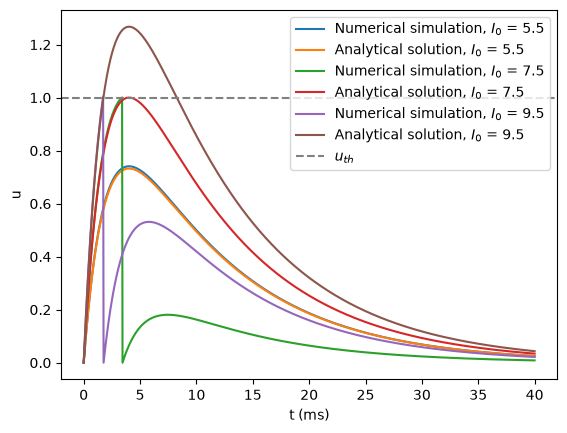

In [52]:
t = np.linspace(0, 40, 1000)
for I0 in [Icrit_theory() - 2, Icrit_theory(), Icrit_theory() + 2]:
    u_num = trap_rule(np.zeros_like(t), t, I0=I0)
    plt.plot(t, u_num, label=f"Numerical simulation, $I_0$ = {np.round(I0, 1)}")
    plt.plot(t, u_theory(t, I0), label=f"Analytical solution, $I_0$ = {np.round(I0, 1)}")

plt.axhline(uth, color="gray", ls="--", label="$u_{th}$")
plt.xlabel("t (ms)"); plt.ylabel("u"); plt.legend()
plt.show()


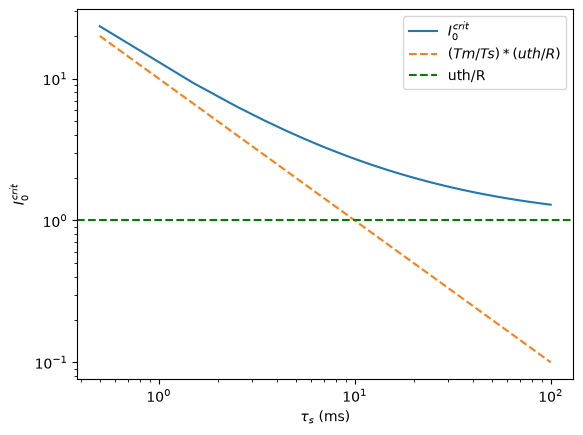

In [53]:
Ts_range = np.linspace(0.5,100,100)
plt.loglog(Ts_range, Icrit_theory(Ts = Ts_range), label="$I_0^{crit}$")
plt.loglog(Ts_range, Tm*uth/(R*Ts_range), "--", label=f"$(Tm/Ts)*(uth/R)$")
plt.axhline(uth/R, color="green", ls="--", label="uth/R")
plt.xlabel("$\\tau_s$ (ms)"); plt.ylabel("$I_0^{crit}$"); plt.legend()
plt.show()


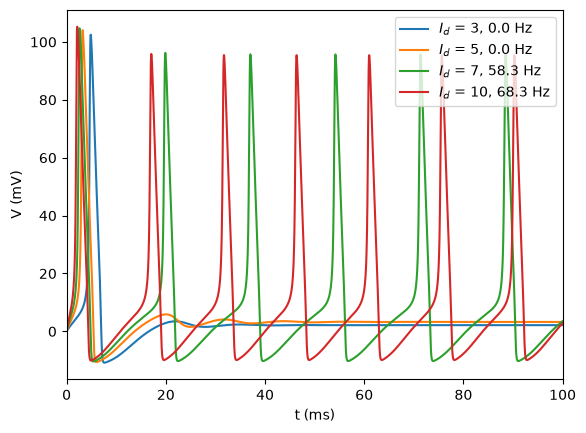

In [ ]:
# Problem 5 - Rheobase and the shape of the f-I curve in HH
import hh_sim as hh

# Experiment: see what the output looks like for a few Id vals
for Id in [3, 5, 7, 10]:
    t, V, spk, rate = hh.hh_sim(Id=Id)
    plt.plot(t, V, label=f"$I_d$ = {Id}, {rate:.1f} Hz")

plt.xlim(0, 100)
plt.xlabel("t (ms)"); 
plt.ylabel("V (mV)"); 
plt.legend()
plt.show()

Rheobase = 5.974 uA/cm^2


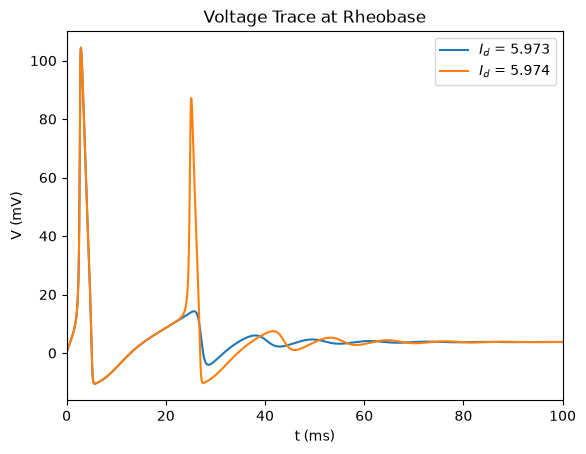

In [97]:
# 5a: Locate the rheobase by bisection
lo, hi = 5, 7 # from experiment above, 5 does not fire repetitively, 7 does

while hi - lo > 0.001:
    mid = (lo + hi) / 2

    _,_,_,rate_mid = hh.hh_sim(Id=mid, skipfrac=0)

    if rate_mid > 0:
        hi = mid
    else:
        lo = mid

t_lo,V_lo,_,_ = hh.hh_sim(Id=lo)
t_hi,V_hi,_,_ = hh.hh_sim(Id=hi)

rb = hi
print(f"Rheobase = {rb:.3f} uA/cm^2")

plt.plot(t_lo, V_lo, label=f"$I_d$ = {lo:.3f}")
plt.plot(t_hi, V_hi, label=f"$I_d$ = {hi:.3f}")
plt.xlim(0, 100)
plt.title("Voltage Trace at Rheobase")
plt.xlabel("t (ms)"); 
plt.ylabel("V (mV)"); 
plt.legend()
plt.show()


Onset rate = 48.309 Hz


/var/folders/7c/hwzp1mjj72sbl2csmq_n0bn00000gn/T/ipykernel_75051/1579953082.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


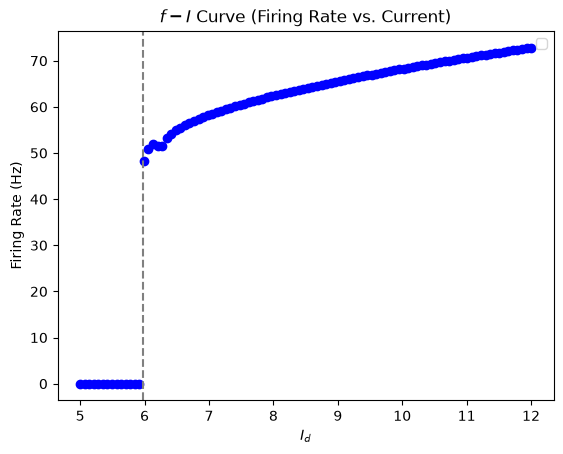

In [102]:
# 5b: compute firing rate for currents in [rheobase, 2*rheobase]. Plot f-I curve. Report the onset rate to 3 digits.
Ids = np.linspace(np.floor(rb), np.ceil(2*rb), 100)
onset_rate = 0

for i, Id in enumerate(Ids):
    _, _, _, rate = hh.hh_sim(Id=Id, skipfrac=0)
    plt.plot(Id, rate, 'o', color='blue')

    if Id > 0 and onset_rate == 0:
        onset_rate = rate

print(f"Onset rate = {onset_rate:.3f} Hz")

plt.legend()
plt.title("$f-I$ Curve (Firing Rate vs. Current)")
plt.xlabel("$I_d$")
plt.ylabel("Firing Rate (Hz)")
plt.axvline(rb, color="gray", ls="--", label="Rheobase")
plt.show()

# The rate switches on at a nonzero value, resembling the Hopf bifurcation from 2 more than the saddle-node bifurcation from 3. The physiological consequence is that in HH, there *is* a minimum rate of firing; unlike in the QIF, you cannot have arbitrarily infrequent firing.

  gK (mS/cm^2)       Rheobase
      36            5.974
      30            2.675


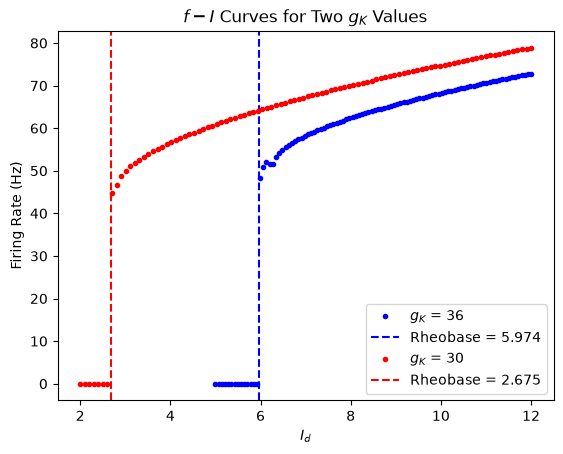

In [103]:
# c: rerun analysis with gK = 36 mS/cm^2, instead of 30. 

def find_rheobase(lo, hi, gK):
    while hi - lo > 0.001:
        mid = (lo + hi) / 2

        _,_,_,rate_mid = hh.hh_sim(Id=mid, gK=gK, skipfrac=0)

        if rate_mid > 0:
            hi = mid
        else:
            lo = mid

    return hi

rb_30 = find_rheobase(2, 3, gK=30)

print(f"  gK (mS/cm^2)       Rheobase")
print(f"      36            {rb:.3f}")
print(f"      30            {rb_30:.3f}")

for gK, rheo, color in [(36, rb, "blue"), (30, rb_30, "red")]:
    Ids = np.linspace(np.floor(rheo), 12, 100)
    rates = [hh.hh_sim(Id=Id, gK=gK, skipfrac=0)[3] for Id in Ids]

    plt.plot(Ids, rates, 'o', ms=3, color=color, label=f"$g_K$ = {gK}")
    plt.axvline(rheo, color=color, ls="--", label=f"Rheobase = {rheo:.3f}")

plt.title("$f-I$ Curves for Two $g_K$ Values")
plt.xlabel("$I_d$")
plt.ylabel("Firing Rate (Hz)")
plt.legend()
plt.show()
